In [1]:
# xG Model: 2018 FIFA World Cup

# A simple expected-goals (xG) model built with StatsBomb open data (64 matches), SQL (DuckDB) and logistic regression. The goal is to estimate how likely a shot is to become a goal and to compare the result with StatsBomb's own xG.

# Data scope: 1,638 shots (135 goals), excluding penalties and penalty shootouts.

import os
import numpy as np
import pandas as pd
import duckdb
from statsbombpy import sb
from mplsoccer import VerticalPitch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

if os.path.exists("events.pkl"):
    events = pd.read_pickle("events.pkl")
else:
    matches = sb.matches(competition_id=43, season_id=3)
    events = pd.concat([sb.events(match_id=m) for m in matches.match_id])
    events.to_pickle("events.pkl")

shots = events[events.type == "Shot"][
    ["match_id", "team", "player", "period", "minute", "location",
     "shot_outcome", "shot_body_part", "shot_type",
     "shot_statsbomb_xg"]].copy()
shots["x"] = shots.location.str[0]
shots["y"] = shots.location.str[1]
shots = shots[shots.period < 5].drop(columns="location")
print(len(shots))   

1667


In [2]:
## 1. Exploration (SQL)

# Goal rate by distance, shot angle and body part.

# - Goal rate falls steadily with distance: 37.7% (0-6 yards) down to 2.8% (25+ yards).
# - Goal rate rises with shot angle: 3.5% (10-20°) up to 23.6% (40°+).
# - Headers have the highest raw goal rate (10.3%), but they are taken much closer to goal. The model corrects for this later.

duckdb.sql("""
    SELECT
        CASE
            WHEN d < 6  THEN '0-6'
            WHEN d < 12 THEN '6-12'
            WHEN d < 18 THEN '12-18'
            WHEN d < 25 THEN '18-25'
            ELSE '25+'
        END AS distance_bucket,
        COUNT(*) AS shots_n,
        AVG(CASE WHEN shot_outcome = 'Goal' THEN 1.0 ELSE 0 END) AS goal_rate
    FROM (
        SELECT *, SQRT(POWER(120 - x, 2) + POWER(40 - y, 2)) AS d
        FROM shots
        WHERE shot_type != 'Penalty'
    )
    GROUP BY 1
    ORDER BY MIN(d)
""").show()

┌─────────────────┬─────────┬─────────────────────┐
│ distance_bucket │ shots_n │      goal_rate      │
│     varchar     │  int64  │       double        │
├─────────────────┼─────────┼─────────────────────┤
│ 0-6             │      53 │ 0.37735849056603776 │
│ 6-12            │     343 │ 0.16034985422740525 │
│ 12-18           │     375 │                0.08 │
│ 18-25           │     398 │ 0.04271356783919598 │
│ 25+             │     469 │ 0.02771855010660981 │
└─────────────────┴─────────┴─────────────────────┘



In [3]:
duckdb.sql("""
    SELECT
        CASE
            WHEN a < 10 THEN '0-10'
            WHEN a < 20 THEN '10-20'
            WHEN a < 40 THEN '20-40'
            ELSE '40+'
        END AS angle_bucket,
        COUNT(*) AS shots_n,
        AVG(CASE WHEN shot_outcome = 'Goal' THEN 1.0 ELSE 0 END) AS goal_rate
    FROM (
        SELECT *,
            DEGREES(ATAN2(8 * (120 - x), POWER(120 - x, 2) + POWER(40 - y, 2) - 16)) AS a
        FROM shots
        WHERE shot_type != 'Penalty'
    )
    GROUP BY 1
    ORDER BY MIN(a)
""").show()

┌──────────────┬─────────┬─────────────────────┐
│ angle_bucket │ shots_n │      goal_rate      │
│   varchar    │  int64  │       double        │
├──────────────┼─────────┼─────────────────────┤
│ 0-10         │      55 │ 0.03636363636363636 │
│ 10-20        │     821 │ 0.03532277710109622 │
│ 20-40        │     512 │         0.087890625 │
│ 40+          │     250 │               0.236 │
└──────────────┴─────────┴─────────────────────┘



In [4]:
duckdb.sql("""
    SELECT
        shot_body_part,
        COUNT(*) AS shots_n,
        AVG(CASE WHEN shot_outcome = 'Goal' THEN 1.0 ELSE 0 END) AS goal_rate
    FROM shots
    WHERE shot_type != 'Penalty'
    GROUP BY 1
    ORDER BY shots_n DESC
""").show()

┌────────────────┬─────────┬─────────────────────┐
│ shot_body_part │ shots_n │      goal_rate      │
│    varchar     │  int64  │       double        │
├────────────────┼─────────┼─────────────────────┤
│ Right Foot     │     825 │ 0.07515151515151515 │
│ Left Foot      │     489 │   0.081799591002045 │
│ Head           │     310 │  0.1032258064516129 │
│ Other          │      14 │ 0.07142857142857142 │
└────────────────┴─────────┴─────────────────────┘



In [5]:
## 2. Features

# Distance to goal centre, shot angle (the angle between the two posts as seen from the ball), body part (header or not), pressure, first-time shot, play pattern and shot technique. Penalties (29) and shootout kicks (39) are excluded.

cols = ["match_id", "period", "location", "play_pattern", "under_pressure",
        "shot_outcome", "shot_body_part", "shot_type", "shot_technique",
        "shot_first_time", "shot_statsbomb_xg", "shot_freeze_frame"]
cols = [c for c in cols if c in events.columns]

s2 = events[events.type == "Shot"][cols].copy()
s2 = s2[(s2.period < 5) & (s2.shot_type != "Penalty")].copy()
s2["x"] = s2.location.str[0]
s2["y"] = s2.location.str[1]
s2["distance"] = np.sqrt((120 - s2.x)**2 + (40 - s2.y)**2)
s2["angle"] = np.degrees(np.arctan2(8 * (120 - s2.x),
                       (120 - s2.x)**2 + (40 - s2.y)**2 - 16))
s2["pressure"] = s2.under_pressure.fillna(False).astype(int)
s2["first_time"] = s2.shot_first_time.fillna(False).astype(int)
s2["goal"] = (s2.shot_outcome == "Goal").astype(int)
print(len(s2), s2.goal.sum())

1638 135


In [6]:
## 3. Freeze frame features

# From the freeze frame at the moment of the shot I computed the number of defenders inside the triangle between the ball and the posts, the goalkeeper's distance from the ball and his offset from the goal centre.

def ff_features(row):
    ff = row.shot_freeze_frame
    if not isinstance(ff, list):
        return pd.Series({"n_defenders": np.nan, "gk_distance": np.nan,
                          "gk_offset": np.nan})
    bx, by = row.x, row.y
    P1, P2 = (120, 36), (120, 44)

    def side(a, b, c):
        return (a[0]-c[0])*(b[1]-c[1]) - (b[0]-c[0])*(a[1]-c[1])

    def in_cone(p):
        d1 = side(p, (bx, by), P1)
        d2 = side(p, P1, P2)
        d3 = side(p, P2, (bx, by))
        neg = (d1 < 0) or (d2 < 0) or (d3 < 0)
        pos = (d1 > 0) or (d2 > 0) or (d3 > 0)
        return not (neg and pos)

    n_def, gk = 0, None
    for o in ff:
        if o["teammate"]:
            continue
        loc = o["location"]
        if o["position"]["name"] == "Goalkeeper":
            gk = loc
        elif in_cone(loc):
            n_def += 1
    return pd.Series({
        "n_defenders": n_def,
        "gk_distance": np.hypot(gk[0]-bx, gk[1]-by) if gk else np.nan,
        "gk_offset": abs(gk[1]-40) if gk else np.nan})

ffd = s2.apply(ff_features, axis=1)
print(ffd.isna().mean())
print(ffd.describe().round(2))

n_defenders    0.000000
gk_distance    0.000611
gk_offset      0.000611
dtype: float64
       n_defenders  gk_distance  gk_offset
count      1638.00      1637.00    1637.00
mean          0.79        17.22       1.71
std           0.95         9.10       1.65
min           0.00         1.00       0.00
25%           0.00         9.43       1.00
50%           1.00        16.28       1.00
75%           1.00        24.08       2.00
max           6.00        60.83      12.00


In [7]:
for c in ffd.columns:
    s2[c] = ffd[c].fillna(ffd[c].median())

cat_cols = ["shot_body_part", "shot_type", "play_pattern", "shot_technique"]
cat_cols = [c for c in cat_cols if c in s2.columns]
num_cols = ["distance", "angle", "pressure", "first_time"]
ff_cols = ["n_defenders", "gk_distance", "gk_offset"]

def run_cv(columns):
    Xm = pd.get_dummies(s2[columns + cat_cols], columns=cat_cols,
                        drop_first=True).astype(float)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    p = cross_val_predict(pipe, Xm, s2.goal, groups=s2.match_id,
                          cv=GroupKFold(n_splits=5),
                          method="predict_proba")[:, 1]
    return Xm, pipe, p

for name, features in [("Without freeze frame", num_cols),
                       ("With freeze frame", num_cols + ff_cols)]:
    Xm, pipe, p = run_cv(features)
    print(name, "| AUC:", round(roc_auc_score(s2.goal, p), 4),
          "| log loss:", round(log_loss(s2.goal, p), 4),
          "| xG total:", round(p.sum(), 1))

Without freeze frame | AUC: 0.761 | log loss: 0.2489 | xG total: 134.9
With freeze frame | AUC: 0.7559 | log loss: 0.251 | xG total: 135.4


In [8]:
## 4. Feature set comparison (5x repeated, grouped CV)

# Folds are grouped by match, so shots from the same match never appear in both training and test data.

# | Feature set | AUC | Log loss |
# |---|---|---|
# | Distance, angle, header | 0.748 ± 0.004 | 0.2508 |
# | + defenders in triangle | 0.748 ± 0.004 | 0.2504 |
# | + goalkeeper distance | 0.738 ± 0.005 | 0.2536 |
# | + both | 0.739 ± 0.005 | 0.2530 |

# **Finding:** the extra freeze frame features did not improve the model. Goalkeeper distance lowered AUC. With only 135 goals, additional features may mostly add noise (this is a hypothesis, not tested). I kept the simple three-feature model.

s2["header"] = (s2.shot_body_part == "Head").astype(int)

feature_sets = {
    "Base (distance, angle, header)": ["distance", "angle", "header"],
    "+ defenders": ["distance", "angle", "header", "n_defenders"],
    "+ goalkeeper": ["distance", "angle", "header", "gk_distance"],
    "+ both": ["distance", "angle", "header", "n_defenders", "gk_distance"],
}

for name, features in feature_sets.items():
    aucs, lls = [], []
    for seed in range(5):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        pipe = make_pipeline(StandardScaler(),
                             LogisticRegression(C=1.0, max_iter=2000))
        p = cross_val_predict(pipe, s2[features], s2.goal, groups=s2.match_id,
                              cv=cv, method="predict_proba")[:, 1]
        aucs.append(roc_auc_score(s2.goal, p))
        lls.append(log_loss(s2.goal, p))
    print(f"{name:28s} AUC {np.mean(aucs):.3f} ± {np.std(aucs):.3f} | "
          f"log loss {np.mean(lls):.4f}")

Base (distance, angle, header) AUC 0.748 ± 0.004 | log loss 0.2508
+ defenders                  AUC 0.748 ± 0.004 | log loss 0.2504
+ goalkeeper                 AUC 0.738 ± 0.005 | log loss 0.2536
+ both                       AUC 0.739 ± 0.005 | log loss 0.2530


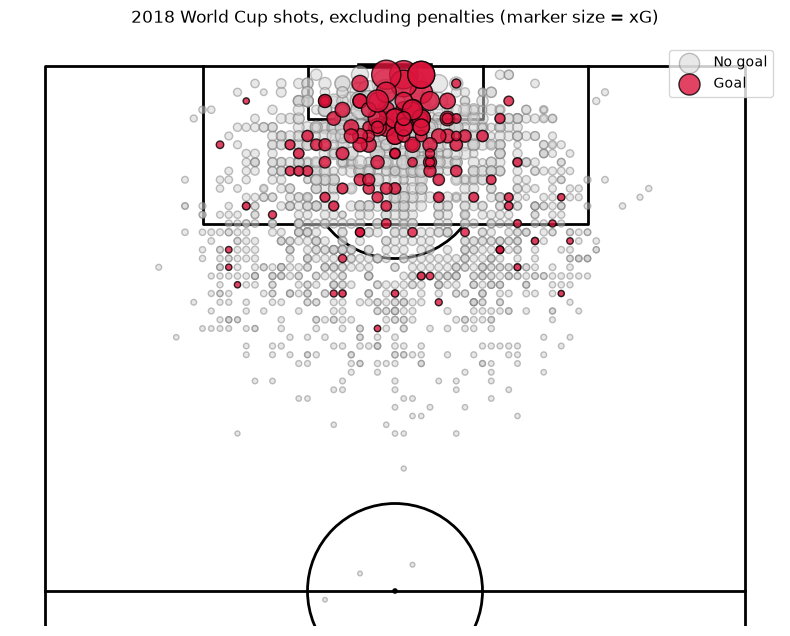

In [9]:
## 5. Shot map

# Marker size shows predicted xG. High-xG shots and goals cluster close to the goal.

features = ["distance", "angle", "header"]
ps = []
for seed in range(5):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    ps.append(cross_val_predict(pipe, s2[features], s2.goal, groups=s2.match_id,
                                cv=cv, method="predict_proba")[:, 1])
s2["xg"] = np.mean(ps, axis=0)

pitch = VerticalPitch(pitch_type="statsbomb", half=True,
                      pitch_color="white", line_color="black")
fig, ax = pitch.draw(figsize=(8, 7))
misses = s2[s2.goal == 0]
scored = s2[s2.goal == 1]
pitch.scatter(misses.x, misses.y, s=misses.xg * 500 + 10, c="lightgray",
              edgecolors="gray", alpha=0.5, ax=ax, label="No goal")
pitch.scatter(scored.x, scored.y, s=scored.xg * 500 + 10, c="crimson",
              edgecolors="black", alpha=0.8, ax=ax, label="Goal")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.98))
ax.set_title("2018 World Cup shots, excluding penalties (marker size = xG)")
fig.savefig("shot_map.png", dpi=200, bbox_inches="tight")

In [10]:
## 6. Final model vs. StatsBomb xG

# | | AUC | Log loss |
# |---|---|---|
# | Constant probability (baseline) | 0.5 | 0.2846 |
# | This model | 0.748 | 0.2506 |
# | StatsBomb xG | 0.782 | 0.2373 |

# **Findings**
# - The model clearly beats the baseline, but StatsBomb's xG ranks shots better (AUC 0.782 vs 0.748). I did not test why. StatsBomb likely uses more inputs and more training data, but adding freeze frame features to my model did not close the gap.
# - Odds ratios: each extra yard of distance lowers the odds of a goal by about 8% (0.922), each extra degree of angle raises them by about 2.4% (1.024), and a header has about 57% lower odds than a foot shot at the same position (0.432).
# - Calibration is good in four of five xG groups. In the third group the model predicts 5.7% while the observed rate is 3.4% (328 shots); this may be chance.
# - The model's total xG matches the 135 goals only because it was fitted on the same tournament, so this is not evidence of better calibration than StatsBomb.

print("Final model  | AUC:", round(roc_auc_score(s2.goal, s2.xg), 4),
      "| log loss:", round(log_loss(s2.goal, s2.xg), 4),
      "| xG:", round(s2.xg.sum(), 1))
print("StatsBomb    | AUC:", round(roc_auc_score(s2.goal, s2.shot_statsbomb_xg), 4),
      "| log loss:", round(log_loss(s2.goal, s2.shot_statsbomb_xg), 4),
      "| xG:", round(s2.shot_statsbomb_xg.sum(), 1))
base = np.full(len(s2), s2.goal.mean())
print("Baseline (constant probability) | log loss:", round(log_loss(s2.goal, base), 4))
print("Actual goals:", s2.goal.sum())

s2["bucket"] = pd.qcut(s2.xg, 5, duplicates="drop")
print(s2.groupby("bucket", observed=True).agg(
    n_shots=("goal", "size"), predicted=("xg", "mean"), actual=("goal", "mean"),
    sb_xg=("shot_statsbomb_xg", "mean")).round(3))

final = LogisticRegression(max_iter=2000).fit(s2[features], s2.goal)
print(dict(zip(features, np.exp(final.coef_[0]).round(3))), "(odds ratios)")

Final model  | AUC: 0.7482 | log loss: 0.2506 | xG: 135.0
StatsBomb    | AUC: 0.7815 | log loss: 0.2373 | xG: 150.0
Baseline (constant probability) | log loss: 0.2846
Actual goals: 135
                   n_shots  predicted  actual  sb_xg
bucket                                              
(0.00059, 0.0293]      328      0.021   0.024  0.017
(0.0293, 0.0457]       327      0.037   0.043  0.037
(0.0457, 0.0691]       328      0.057   0.034  0.065
(0.0691, 0.111]        327      0.088   0.083  0.108
(0.111, 0.862]         328      0.209   0.229  0.230
{'distance': np.float64(0.922), 'angle': np.float64(1.024), 'header': np.float64(0.432)} (odds ratios)
